# 02 · Análisis exploratorio (EDA)
Distribución de clases, muestrarios, tamaño y color de las imágenes, y una prueba cuantitativa de atajos (*shortcut learning*). Cada figura se acompaña de su interpretación.

Datos de entrada (salen del notebook 01): `manifest_final.csv`, `bracol_crops.zip`, `jmuben_sample/` y `jmuben_totales.csv`.
**BRACOL = recortes de caja** (train/val/test oficiales, depurados) · **JMuBEN = 500 hojas completas por clase** (validación externa).

## 0 · Entorno y carga de datos

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import sys, os, zipfile, random
PROJECT = '/content/drive/MyDrive/proyecto_cafe_cnn'
os.environ['PROJECT_DIR'] = PROJECT
sys.path.insert(0, f'{PROJECT}/src')
import common as C
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
P = C.paths()
SEED = 42
C.set_seed(SEED)
plt.rcParams.update({'font.family': 'serif', 'figure.dpi': 120})

# Restaurar los recortes de BRACOL en disco local si es una sesión nueva
OUT = '/content/bracol_crops'
CROPS_ZIP = f"{P['data/processed']}/bracol_crops.zip"
if not os.path.exists(OUT):
    with zipfile.ZipFile(CROPS_ZIP) as z:
        z.extractall(OUT)
    print('Recortes restaurados desde Drive')

man = pd.read_csv(f"{P['data/processed']}/manifest_final.csv")
faltan = (~man.path.map(os.path.exists)).sum()
assert faltan == 0, f'{faltan} rutas del manifest no existen'
man['lado'] = man[['width', 'height']].max(axis=1)
man['grupo'] = man.source + ' · ' + man.label
print(man.groupby(['source', 'split']).size().unstack(fill_value=0))

Mounted at /content/drive
Recortes restaurados desde Drive
split   external  test  train   val
source                             
bracol         0   848   5689  1554
jmuben      2500     0      0     0


## 1 · Distribución de clases

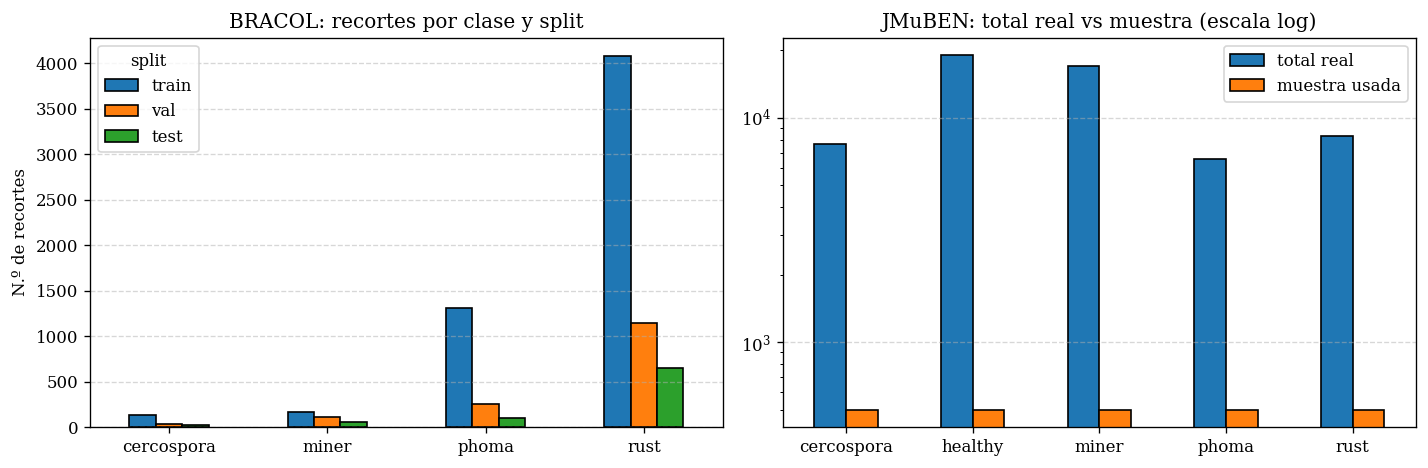

Razón de desbalance en train (máx/mín): 30.9


split,train,val,test,total
label,,,,
cercospora,132,39,29,200
miner,171,110,59,340
phoma,1310,254,107,1671
rust,4076,1151,653,5880


In [2]:
# Fig. 1 · Distribución de clases: BRACOL por split y JMuBEN (total real vs muestra)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bt = (man[man.source == 'bracol'].groupby(['label', 'split']).size().unstack(fill_value=0)[['train', 'val', 'test']])
bt.plot(kind='bar', ax=ax[0], edgecolor='black', rot=0)
ax[0].set_title('BRACOL: recortes por clase y split'); ax[0].set_ylabel('N.º de recortes'); ax[0].set_xlabel('')
ax[0].grid(axis='y', ls='--', alpha=.5)

tot = pd.read_csv(f"{P['results']}/jmuben_totales.csv", index_col=0)['imagenes']
samp = man[man.source == 'jmuben'].groupby('label').size()
pd.DataFrame({'total real': tot, 'muestra usada': samp}).plot(kind='bar', ax=ax[1], edgecolor='black', rot=0, logy=True)
ax[1].set_title('JMuBEN: total real vs muestra (escala log)'); ax[1].set_xlabel('')
ax[1].grid(axis='y', ls='--', alpha=.5)
plt.tight_layout(); plt.savefig(f"{P['figures']}/eda_distribucion_clases.png", dpi=300); plt.show()

train = man[(man.source == 'bracol') & (man.split == 'train')].label.value_counts()
print('Razón de desbalance en train (máx/mín):', round(train.max() / train.min(), 1))
display(bt.assign(total=bt.sum(axis=1)))

In [3]:
# Pesos de clase "balanced" que usará el entrenamiento (mismo cálculo que run_experiment)
from sklearn.utils.class_weight import compute_class_weight
classes = sorted(train.index)
y_tr = man[(man.source == 'bracol') & (man.split == 'train')].label.map({c: i for i, c in enumerate(classes)}).values
w = compute_class_weight('balanced', classes=np.arange(len(classes)), y=y_tr)
display(pd.DataFrame({'clase': classes, 'n_train': [train[c] for c in classes], 'peso': w.round(2)}))

,clase,n_train,peso
0,cercospora,132,10.77
1,miner,171,8.32
2,phoma,1310,1.09
3,rust,4076,0.35


## 2 · Muestrarios

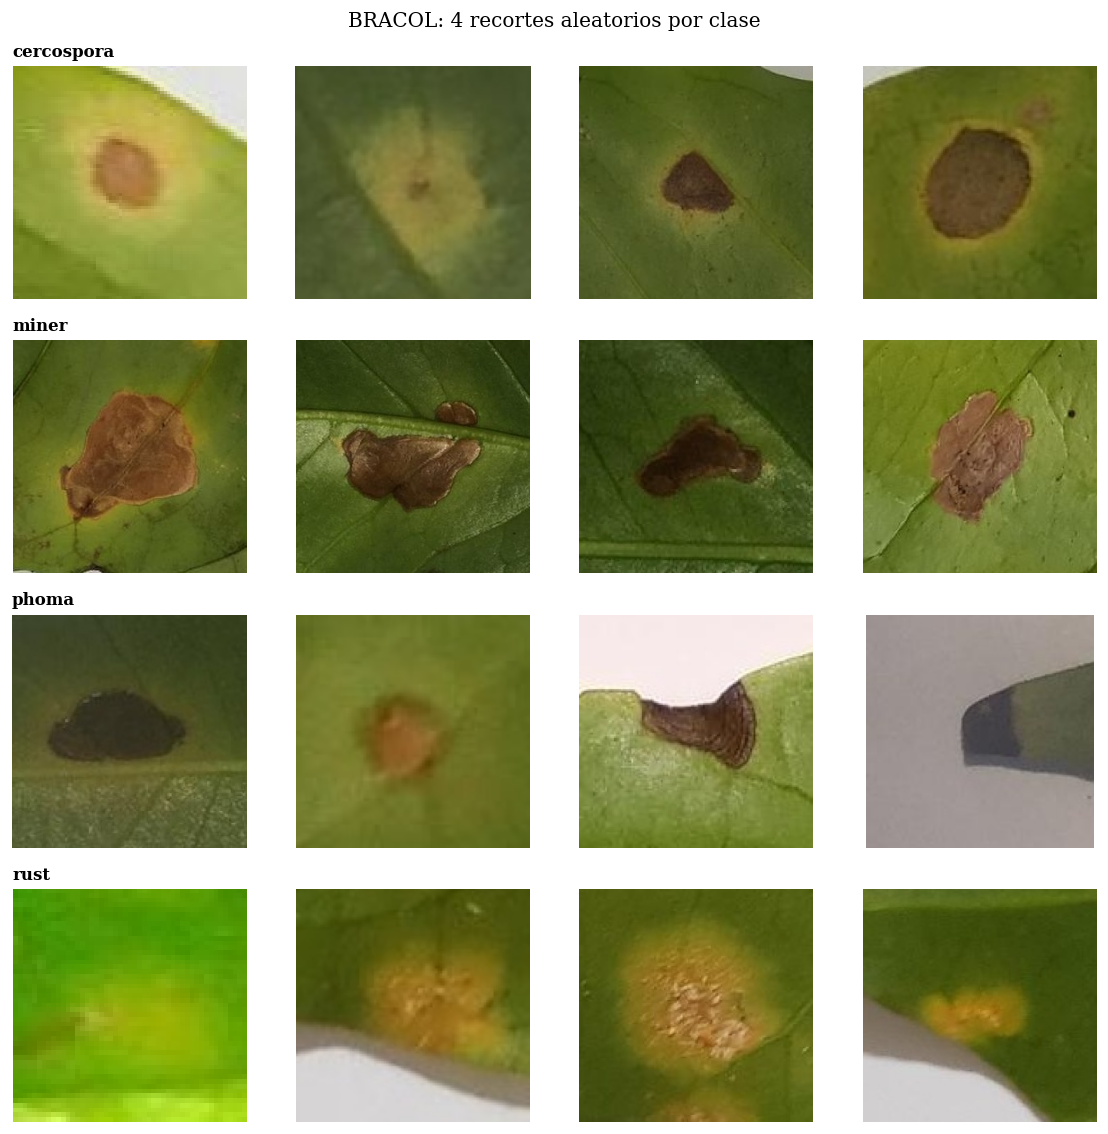

In [4]:
def muestrario(df, titulo, fname, n=4, size=(2.4, 2.4)):
    labs = sorted(df.label.unique()); rng = random.Random(SEED)
    fig, axes = plt.subplots(len(labs), n, figsize=(n * size[0], len(labs) * size[1]))
    axes = np.atleast_2d(axes)
    for i, l in enumerate(labs):
        ps = df[df.label == l].path.tolist(); ps = rng.sample(ps, min(n, len(ps)))
        for j in range(n):
            axes[i, j].axis('off')
            if j < len(ps): axes[i, j].imshow(Image.open(ps[j]).convert('RGB'))
            if j == 0: axes[i, j].set_title(l, loc='left', fontsize=10, fontweight='bold')
    plt.suptitle(titulo); plt.tight_layout()
    plt.savefig(f"{P['figures']}/{fname}", dpi=300); plt.show()

# Fig. 2a · BRACOL (recortes, tal como los verá la red antes de redimensionar)
muestrario(man[(man.source == 'bracol') & (man.split == 'train')], 'BRACOL: 4 recortes aleatorios por clase', 'eda_muestrario_bracol.png')

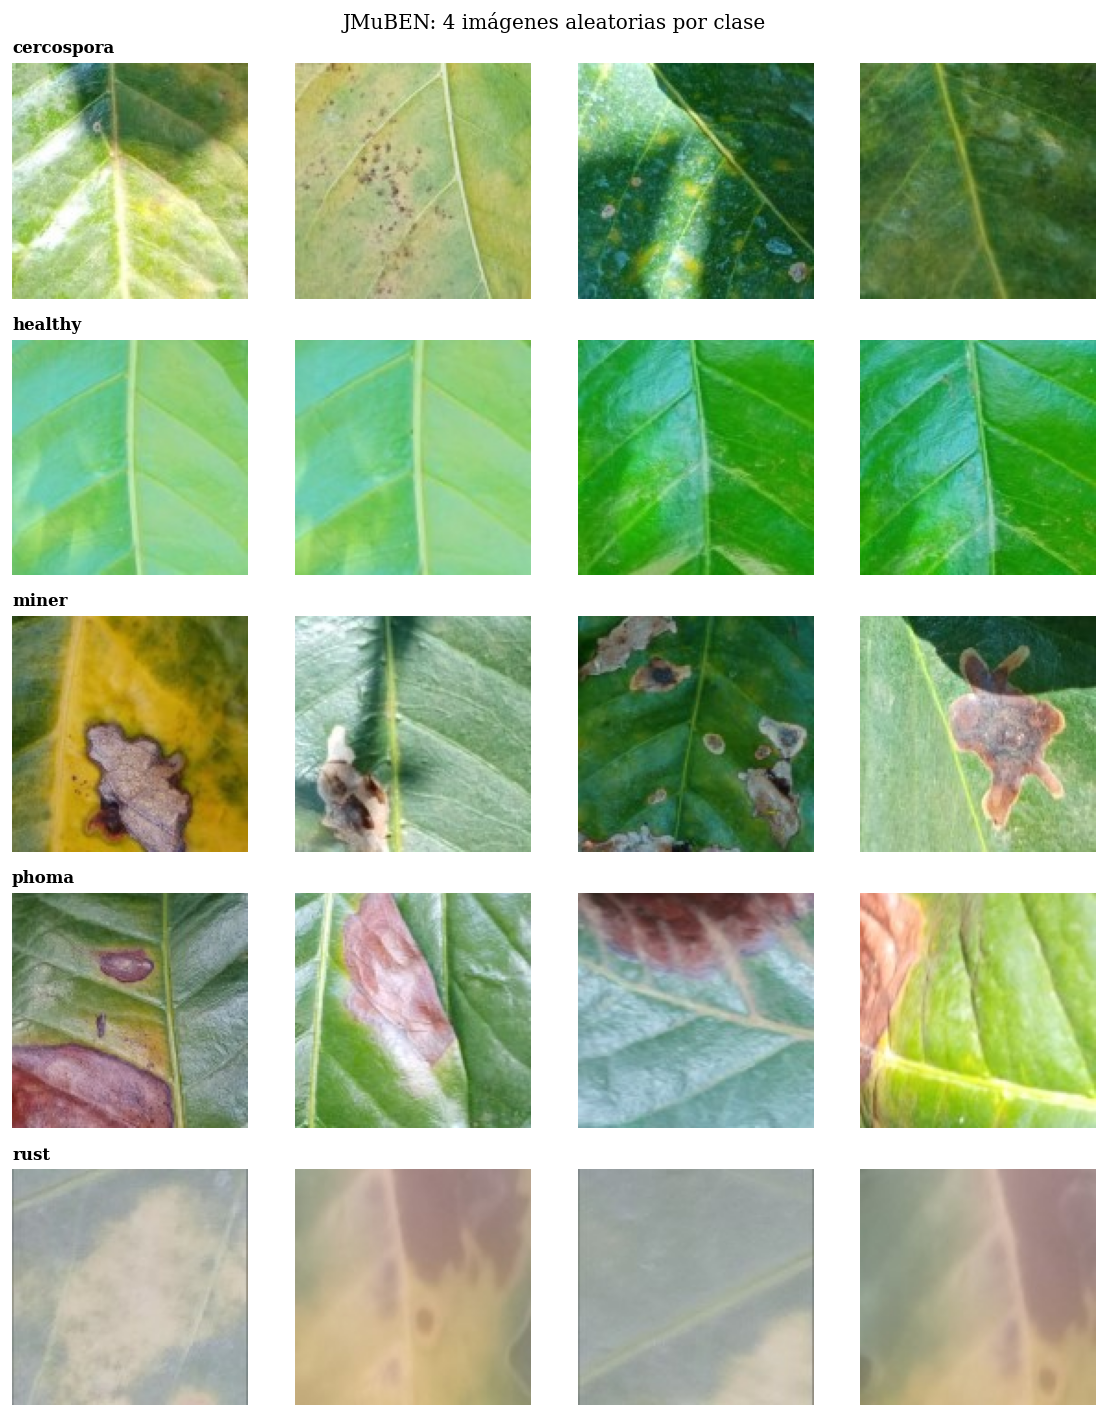

In [5]:
# Fig. 2b · JMuBEN (hojas completas, incluye Healthy)
muestrario(man[man.source == 'jmuben'], 'JMuBEN: 4 imágenes aleatorias por clase', 'eda_muestrario_jmuben.png')

## 3 · Tamaño: ¿qué cambia al redimensionar a 224×224?

/tmp/ipykernel_597/3150826495.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([man.loc[man.grupo == g, 'lado'] for g in orden], labels=orden, showfliers=False)


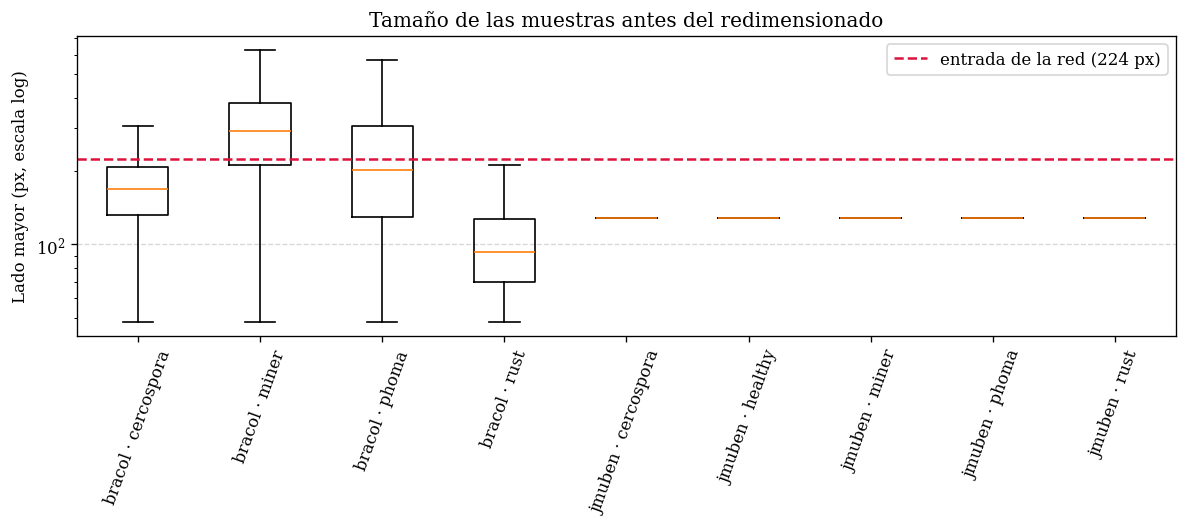

/tmp/ipykernel_597/3150826495.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .join(man.groupby('grupo').apply(lambda d: (d.lado < C.IMG_SIZE).mean()).rename('frac_ampliadas')).round(2))


,mediana,p25,p75,frac_ampliadas
grupo,,,,
bracol · cercospora,168.0,132.00,208.25,0.84
bracol · miner,291.5,210.75,380.75,0.29
bracol · phoma,202.0,129.00,306.00,0.56
bracol · rust,93.0,70.00,127.00,0.94
jmuben · cercospora,128.0,128.00,128.00,0.82
jmuben · healthy,128.0,128.00,128.00,1.00
jmuben · miner,128.0,128.00,128.00,0.93
jmuben · phoma,128.0,128.00,128.00,1.00
jmuben · rust,128.0,128.00,128.00,1.00


In [6]:
# Fig. 3 · Lado mayor (px) por fuente y clase; la línea marca el tamaño de entrada de la red
orden = sorted(man.grupo.unique())
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([man.loc[man.grupo == g, 'lado'] for g in orden], labels=orden, showfliers=False)
ax.axhline(C.IMG_SIZE, color='crimson', ls='--', label=f'entrada de la red ({C.IMG_SIZE} px)')
ax.set_yscale('log'); ax.set_ylabel('Lado mayor (px, escala log)'); ax.tick_params(axis='x', rotation=70)
ax.set_title('Tamaño de las muestras antes del redimensionado'); ax.legend(); ax.grid(axis='y', ls='--', alpha=.5)
plt.tight_layout(); plt.savefig(f"{P['figures']}/eda_tamanos.png", dpi=300); plt.show()

res = (man.groupby('grupo').lado.agg(mediana='median', p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75))
         .join(man.groupby('grupo').apply(lambda d: (d.lado < C.IMG_SIZE).mean()).rename('frac_ampliadas')).round(2))
display(res)

## 4 · Color medio: ¿el fondo o la iluminación delatan la fuente o la clase?

  0%|          | 0/10591 [00:00<?, ?it/s]

/tmp/ipykernel_597/2564498709.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[k].boxplot([man.loc[man.grupo == g, ch] for g in orden], labels=orden, showfliers=False)
/tmp/ipykernel_597/2564498709.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[k].boxplot([man.loc[man.grupo == g, ch] for g in orden], labels=orden, showfliers=False)
/tmp/ipykernel_597/2564498709.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[k].boxplot([man.loc[man.grupo == g, ch] for g in orden], labels=orden, showfliers=False)


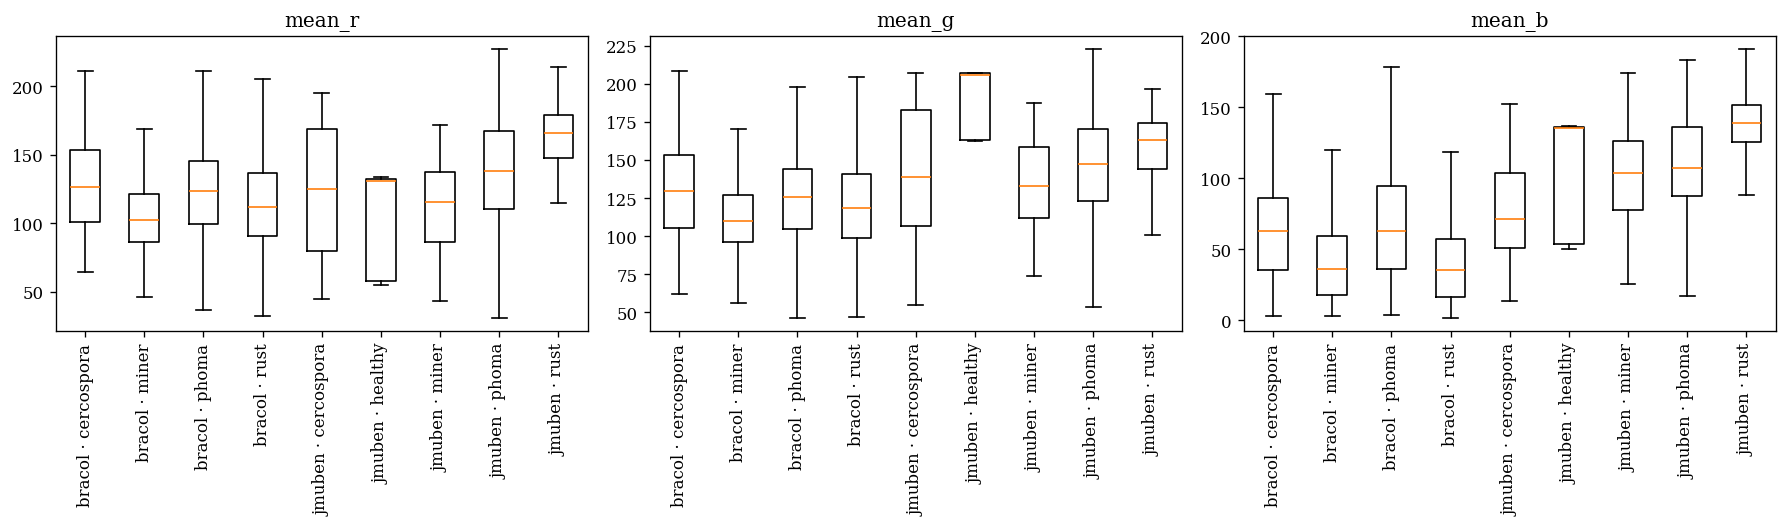

In [9]:
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

COLF = f"{P['results']}/eda_color.csv"
if os.path.exists(COLF):
    col = pd.read_csv(COLF)
else:
    def mean_rgb(p):
        with Image.open(p) as im:
            return np.asarray(im.convert('RGB').resize((32, 32)), dtype=np.float32).reshape(-1, 3).mean(0)
    with ThreadPoolExecutor(max_workers=16) as ex:
        feats = list(tqdm(ex.map(mean_rgb, man.path), total=len(man)))
    col = pd.DataFrame(feats, columns=['mean_r', 'mean_g', 'mean_b'])
    col['path'] = man.path.values
    col.to_csv(COLF, index=False)
man = man.merge(col, on='path', how='left')
assert man[['mean_r', 'mean_g', 'mean_b']].notna().all().all()

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for k, ch in enumerate(['mean_r', 'mean_g', 'mean_b']):
    ax[k].boxplot([man.loc[man.grupo == g, ch] for g in orden], labels=orden, showfliers=False)
    ax[k].set_title(ch); ax[k].tick_params(axis='x', rotation=90)
plt.tight_layout(); plt.savefig(f"{P['figures']}/eda_color_medio.png", dpi=300); plt.show()

## 5 · Prueba cuantitativa de atajos (shortcut learning)

In [10]:
# ¿Se puede adivinar la clase SOLO con tamaño y color medio? Si sí, hay riesgo de atajo.
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score
feats = ['lado', 'mean_r', 'mean_g', 'mean_b']
b = man[man.source == 'bracol']
tr, va = b[b.split == 'train'], b[b.split == 'val']
rf = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=SEED, n_jobs=-1).fit(tr[feats], tr.label)
du = DummyClassifier(strategy='prior').fit(tr[feats], tr.label)
print('macro-F1 en val (BRACOL), solo tamaño+color:', round(f1_score(va.label, rf.predict(va[feats]), average='macro'), 3))
print('macro-F1 en val (BRACOL), azar (prior)     :', round(f1_score(va.label, du.predict(va[feats]), average='macro', zero_division=0), 3))

ex = man[(man.source == 'jmuben') & (man.label.isin(classes))]
print('macro-F1 en JMuBEN (externo), mismo modelo :', round(f1_score(ex.label, rf.predict(ex[feats]), average='macro'), 3))
display(pd.Series(rf.feature_importances_, index=feats, name='importancia').round(3))

macro-F1 en val (BRACOL), solo tamaño+color: 0.397
macro-F1 en val (BRACOL), azar (prior)     : 0.213
macro-F1 en JMuBEN (externo), mismo modelo : 0.113


,importancia
lado,0.359
mean_r,0.193
mean_g,0.202
mean_b,0.245


### Interpretación
- **Desbalance.** En BRACOL domina la roya (4076 recortes frente a 132 de cercospora en train, razón ≈ 31:1; 77 % de la prueba). Por eso se usa macro-F1, `class_weight` balanceado y se reporta el IC por bootstrap. Cercospora y Miner tienen pocos ejemplos en test (29 y 59).
- **Tamaño.** La roya llega con la menor resolución (mediana de 93 px; el 94 % se amplía al pasar a 224 px) y Miner con la mayor (291.5 px; 29 % ampliado). Todas las imágenes de JMuBEN miden ~128 px. Si una clase llega mucho más borrosa, el modelo podría separarla por desenfoque y no por la lesión.
- **Cambio de dominio.** BRACOL son recortes de lesión y JMuBEN hojas completas; JMuBEN es más claro y azulado (medianas del canal azul de ~70 a 140 frente a ~35 a 65 en BRACOL).
- **Atajos.** Un modelo que solo ve tamaño y color medio logra macro-F1 de 0.397 en validación (azar: 0.213) y de 0.113 en el conjunto externo: hay señal de atajo dentro de BRACOL que no se transfiere a JMuBEN. Se contrasta con Grad-CAM en el notebook 05.
- **Healthy.** Solo existe en JMuBEN, por lo que no entra en el entrenamiento ni en la métrica externa de 4 clases (limitación).